In [7]:
import numpy as np
import matplotlib.pyplot as plt 

[7.71644483] [-0.13894348]
0.015688973959337615


Text(0.5, 1.0, 'Run #24')

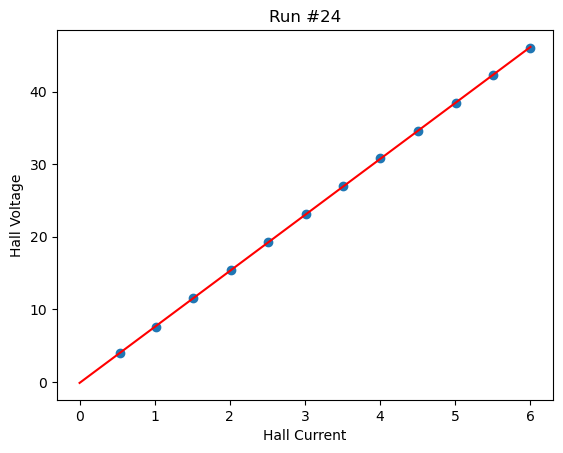

In [8]:
#Run24

current = [0.54, 1.02, 1.51, 2.02, 2.51, 3.01, 3.50,
           4.00, 4.50, 5.01, 5.50, 6.00]

voltage = [4.0, 7.6, 11.5, 15.4, 19.3, 23.2, 27.0,
           30.8, 34.6, 38.5, 42.3, 46.0]


# line of best fit using Linear Least Squares
def LinearLeastSquares(current, voltage):
    x = np.array(current[:])
    y = np.array(voltage[:])
    Sx = np.sum(x)
    Sy = np.sum(y)
    Sx2 = np.sum(x**2)
    Sxy = np.sum(x*y)
    n = len(x)              
    b = [[Sxy],
         [Sy]]

    A_inverse = np.array([[n,  -Sx],
                          [-Sx, Sx2]])

    return (1/(n*Sx2 - Sx**2)) * np.dot(A_inverse, b)


m, c = LinearLeastSquares(current, voltage)
residuals = np.array(voltage) - (m*np.array(current) + c)
sigma_m = np.sqrt(
    np.sum(residuals**2) / (len(current)-2) /
    np.sum((np.array(current) - np.mean(current))**2))
print(m, c)
print(sigma_m)
plt.scatter(current, voltage)

# fit line
x = np.linspace(0, 6, 100)
line = m*x + c
plt.plot(x, line, color='red')     
plt.ylabel('Hall Voltage')
plt.xlabel('Hall Current')
plt.title('Run #24')

[14.38303138] [-0.05478127]
0.018951435387319148


Text(0.5, 1.0, 'Run #25')

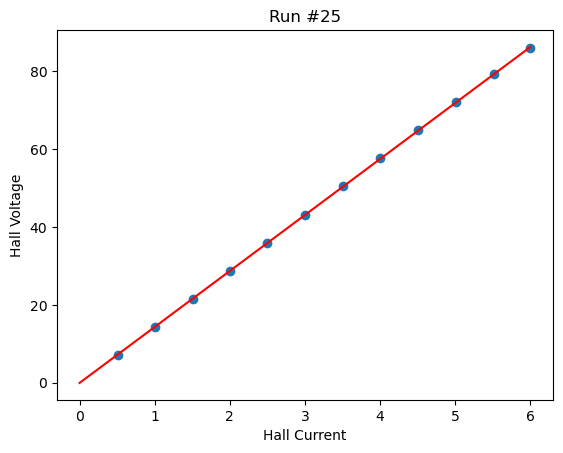

In [9]:
#Run25 (Higher Solenoid Current)

current = [0.51, 1.01, 1.51, 2, 2.5, 3, 3.5, 4, 4.5, 
           5.01, 5.51, 6]
voltage = [7.2, 14.4, 21.6, 28.8, 35.9, 43.1, 50.4, 57.6,
           64.8, 72, 79.2, 86]

m,c = LinearLeastSquares(current, voltage)
print(m, c)

residuals = np.array(voltage) - (m*np.array(current) + c)
sigma_m = np.sqrt(
    np.sum(residuals**2) / (len(current)-2) /
    np.sum((np.array(current) - np.mean(current))**2))

print(sigma_m)

plt.scatter(current, voltage)

#fit line
x = np.linspace(0,6,7)
line = m*x + c
plt.plot(line, color='red')
plt.ylabel('Hall Voltage')
plt.xlabel('Hall Current')
plt.title('Run #25')

[-0.31211124] [-0.26689107]


Text(0.5, 1.0, 'Run #26 (Background Run)')

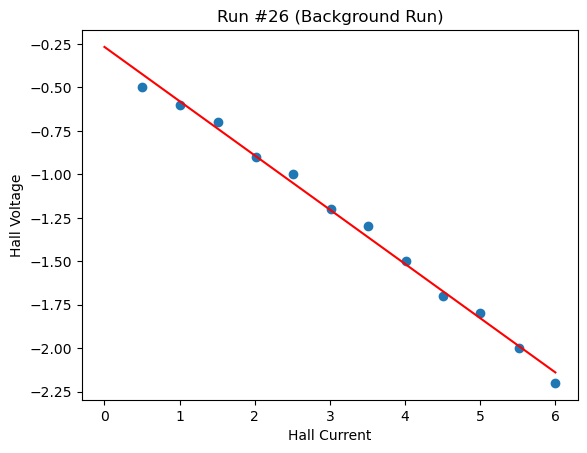

In [12]:
#Run3 (Background, low, 'no', magnetic field)

current = [0.5, 1.01, 1.51, 2.01, 2.51, 3.01, 3.51, 4.01, 4.50, 
           5, 5.51, 6]
voltage = [-0.5, -0.6, -0.7, -0.9, -1, -1.2, -1.3, -1.5, -1.7, 
           -1.8, -2, -2.2]

m,c = LinearLeastSquares(current, voltage)
print(m, c)
plt.scatter(current, voltage)

#fit line
x = np.linspace(0,6,7)
line = m*x + c
plt.plot(line, color='red')
plt.ylabel('Hall Voltage')
plt.xlabel('Hall Current')
plt.title('Run #26 (Background Run)')

Text(0.5, 1.0, 'Cubic Polynomial Fitted Through Data Points')

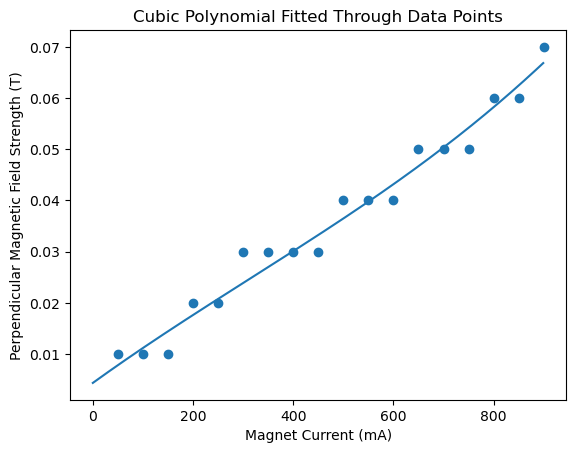

In [15]:
#Section 3.2
#Run27

current = [50, 100, 150, 200, 250, 300, 350, 400, 450, 
           500, 550, 600,650, 700, 750, 800, 850, 900]
B = [0.01, 0.01, 0.01, 0.02, 0.02, 0.03, 0.03, 0.03, 0.03, 0.04, 0.04, 0.04, 
     0.05, 0.05, 0.05, 0.06, 0.06, 0.07]
plt.scatter(current, B)

#fit cubic
x = np.linspace(0, 900, 900)
def f(x):
    return 0.00435 + 7.06e-5*x + (-2.73e-8*(x**2)) + (2.89e-11*(x**3))
plt.plot(f(x))
    
plt.ylabel('Perpendicular Magnetic Field Strength (T)')
plt.xlabel('Magnet Current (mA)')
plt.title('Cubic Polynomial Fitted Through Data Points')



[0.000966] [0.00187458]
0.00046504177543495244


Text(0.5, 1.0, '#Run18')

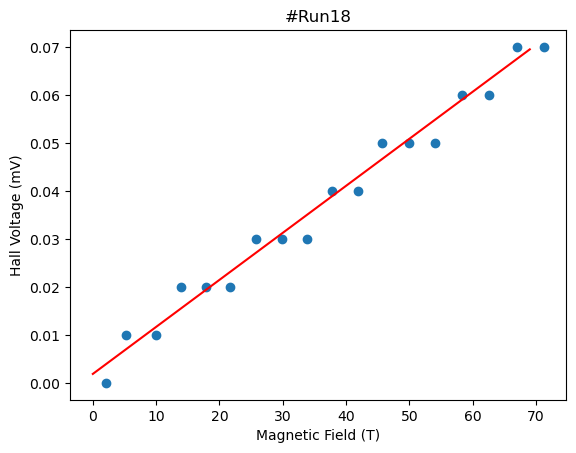

In [19]:
#Run18

hall_voltage = [2.1, 5.3, 10, 13.9, 17.9, 21.7, 25.7, 29.8, 
                33.8, 37.7, 41.8, 45.7, 49.9, 54.1, 58.3, 
                62.5, 66.9, 71.2]

B = [0, 0.01, 0.01, 0.02, 0.02, 0.02, 0.03, 0.03, 0.03,
     0.04, 0.04, 0.05, 0.05, 0.05, 0.06, 0.06, 0.07, 0.07]

m,c = LinearLeastSquares(hall_voltage, B)
print(m, c)
plt.scatter(hall_voltage, B)

# Residuals (CORRECT orientation)
residuals = B - (m*current + c)

# Standard error in slope
sigma_m = np.sqrt(
    np.sum(residuals**2) / (len(B)-2) /
    np.sum((current - np.mean(current))**2)
)
print(sigma_m)

#plot line 
x = np.linspace(0, 70, 70)
line = m*x + c
plt.plot(line, color = 'red')
plt.ylabel('Hall Voltage (mV)')
plt.xlabel('Magnetic Field (T)')
plt.title('#Run18')

[0.00048959] [0.00207155]


Text(0.5, 0, 'Magnetic Field (T)')

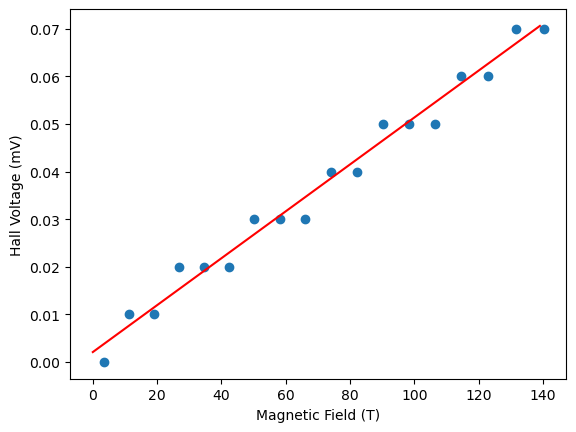

In [13]:
#Run19

hall_voltage = [3.5, 11.3, 18.9, 26.7, 34.6, 42.4, 50.2, 
                58.3, 65.9, 74.1, 82, 90.1, 98.3, 106.3, 
                114.6, 123, 131.5, 140.2]
B = [0, 0.01, 0.01, 0.02, 0.02, 0.02, 0.03, 0.03, 0.03, 
     0.04, 0.04, 0.05, 0.05, 0.05, 0.06, 0.06, 0.07, 0.07]

m,c = LinearLeastSquares(hall_voltage, B)
print(m, c)
plt.scatter(hall_voltage, B)

#plot line 
x = np.linspace(0, 140, 140)
line = m*x + c
plt.plot(line, color = 'red')
plt.ylabel('Hall Voltage (mV)')
plt.xlabel('Magnetic Field (T)')